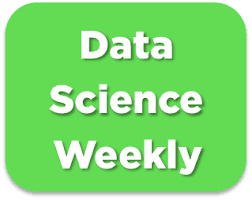

# Import libraries

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
)
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings(
    "ignore", category=DeprecationWarning
)  # to avoid deprecation warnings

import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display

# Read file with labels

In [2]:
df = pd.read_csv("walmart_sales.csv")
print('Set with labels :', df.shape)

Set with labels : (150, 8)


Le dataset est tout petit. Nous devons conserver toutes les lignes pour l'exploiter en machine learning.

# Explore dataset

In [3]:
print(f"Display of dataset: {display(df.head())}")

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,6.0,18-02-2011,1572117.54,NaN,59.61,3.045,214.777523,6.858
1,13.0,25-03-2011,1807545.43,0.0,42.38,3.435,128.616064,7.470
2,17.0,27-07-2012,NaN,0.0,NaN,NaN,130.719581,5.936
3,11.0,NaN,1244390.03,0.0,84.57,NaN,214.556497,7.346
4,6.0,28-05-2010,1644470.66,0.0,78.89,2.759,212.412888,7.092


Display of dataset: None


We observe : 
- uppercases and lowercases on titles
- formats unoptimized : categories (store, holiday_flag) in float, numeric data with different level precision
- unsorted data
- missing data

In [4]:
# Basic stats
print(f"Number of rows : \t dataset {df.shape[0]}")
print(f"Number of columns : \t dataset {df.shape[1]}")

print()
print("Basics statistics: df dataset")
df_desc = df.describe(include='all') # numeric variables and catégorielles
display(df_desc)

print("Percentage of missing values")
df_missing_values = df.isnull().sum()/df.shape[0]*100

print()
print(f"df : \n{df_missing_values}")

Number of rows : 	 dataset 150
Number of columns : 	 dataset 8

Basics statistics: df dataset


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,150.000000,132,1.360000e+02,138.000000,132.000000,136.000000,138.000000,135.000000
unique,NaN,85,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,07-01-2011,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,4,NaN,NaN,NaN,NaN,NaN,NaN
mean,9.866667,NaN,1.249536e+06,0.079710,61.398106,3.320853,179.898509,7.598430
std,6.231191,NaN,6.474630e+05,0.271831,18.378901,0.478149,40.274956,1.577173
min,1.000000,NaN,2.689290e+05,0.000000,18.790000,2.514000,126.111903,5.143000
25%,4.000000,NaN,6.050757e+05,0.000000,45.587500,2.852250,131.970831,6.597500
50%,9.000000,NaN,1.261424e+06,0.000000,62.985000,3.451000,197.908893,7.470000
75%,15.750000,NaN,1.806386e+06,0.000000,76.345000,3.706250,214.934616,8.150000


Percentage of missing values

df : 
Store            0.000000
Date            12.000000
Weekly_Sales     9.333333
Holiday_Flag     8.000000
Temperature     12.000000
Fuel_Price       9.333333
CPI              8.000000
Unemployment    10.000000
dtype: float64


We observe missing values on each columns except store.

In [5]:
print("Duplicate rows:")
df.duplicated().sum()

Duplicate rows:


np.int64(0)

In [6]:
print("Percentage of missing values")
df_missing_values = df.isnull().sum()/df.shape[0]*100

print()
print(f"df : \n{df_missing_values}")

Percentage of missing values

df : 
Store            0.000000
Date            12.000000
Weekly_Sales     9.333333
Holiday_Flag     8.000000
Temperature     12.000000
Fuel_Price       9.333333
CPI              8.000000
Unemployment    10.000000
dtype: float64


Lowercase all columns names

In [7]:
df.columns = df.columns.str.lower()
print(df.columns)

Index(['store', 'date', 'weekly_sales', 'holiday_flag', 'temperature',
       'fuel_price', 'cpi', 'unemployment'],
      dtype='str')


In [8]:
df.columns

Index(['store', 'date', 'weekly_sales', 'holiday_flag', 'temperature',
       'fuel_price', 'cpi', 'unemployment'],
      dtype='str')

### detect outlyers

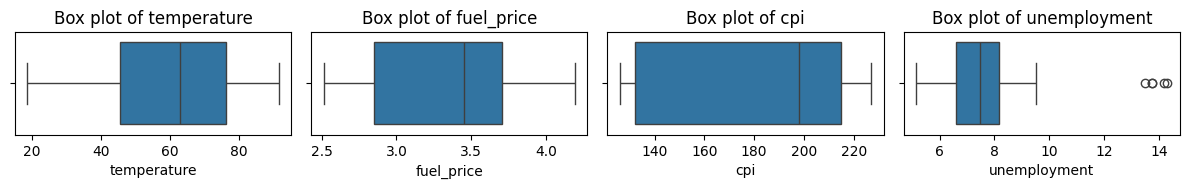

In [9]:
# Create box plots for the 'value', 'useful_area', 'time_on_market', 'interior_quality',
# 'rooms', and 'garages' variables to visually inspect for outliers
plt.figure(figsize=(12, 8))
plt.subplot(5, 4, 1)
sns.boxplot(x=df['temperature'])
plt.title('Box plot of temperature')
plt.subplot(5, 4, 2)
sns.boxplot(x=df['fuel_price'])
plt.title('Box plot of fuel_price')
plt.subplot(5, 4, 3)
sns.boxplot(x=df['cpi'])
plt.title('Box plot of cpi')
plt.subplot(5, 4, 4)
sns.boxplot(x=df['unemployment'])
plt.title('Box plot of unemployment')
plt.tight_layout()
plt.show()

We observe outliers on unemployment.

# EDA

## dataclean

In [10]:
holiday_flag = df.groupby(['store', 'date'])['holiday_flag'].nunique()
variances = holiday_flag[holiday_flag > 1]
print(variances)

Series([], Name: holiday_flag, dtype: int64)


In [11]:
# print(df.nunique())

### missing values

In [12]:
print('Missing values treatment...')
# before = df.nunique()
cols = ['weekly_sales', 'date']
df = df.dropna(subset=cols) # drop lines where target values is missing. 

Missing values treatment...


We never use imputation techniques on the target : it might create some bias in the predictions.

In [13]:
'''# La distribution unemployment est symétrique, proche de la loi normale. Imputation avec la moyenne.
df['unemployment'] = df['unemployment'].fillna(df['unemployment'].mean())'''

"# La distribution unemployment est symétrique, proche de la loi normale. Imputation avec la moyenne.\ndf['unemployment'] = df['unemployment'].fillna(df['unemployment'].mean())"

### Convert data

In [14]:
categories = ['store', 'holiday_flag']

df[categories] = df[categories].astype('Int64') # convert categories in integers, avoid error "Cannot convert non-finite values".

In [15]:
'''categories = ['store', 'holiday_flag']
numeric_cols = ['temperature', 'fuel_price', 'cpi', 'unemployment']


df[categories] = df[categories].fillna(df[categories].mode().iloc[0]).astype(int) # replace missing values by mode, then convert categories in integers, avoid error "Cannot convert non-finite values".
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median()) # replace missing values by median

after = df.nunique()
print("Percentage of missing values")
missing_values = df.isnull().sum()/df.shape[0]*100

print()
print(f"df : \n{missing_values}")'''

'categories = [\'store\', \'holiday_flag\']\nnumeric_cols = [\'temperature\', \'fuel_price\', \'cpi\', \'unemployment\']\n\n\ndf[categories] = df[categories].fillna(df[categories].mode().iloc[0]).astype(int) # replace missing values by mode, then convert categories in integers, avoid error "Cannot convert non-finite values".\ndf[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median()) # replace missing values by median\n\nafter = df.nunique()\nprint("Percentage of missing values")\nmissing_values = df.isnull().sum()/df.shape[0]*100\n\nprint()\nprint(f"df : \n{missing_values}")'

In [16]:
'''compare = after.nunique() - before.nunique()
print(df[df['date'].isna()])'''

"compare = after.nunique() - before.nunique()\nprint(df[df['date'].isna()])"

In [17]:
df.dtypes

store             Int64
date                str
weekly_sales    float64
holiday_flag      Int64
temperature     float64
fuel_price      float64
cpi             float64
unemployment    float64
dtype: object

In [18]:
# Conversion des dates au format date time
type('date')
df['date'] = pd.to_datetime(df['date'], format = "%d-%m-%Y")
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['weekday'] = df['date'].dt.dayofweek
print(df['weekday'].value_counts(dropna=False))

weekday
4    118
Name: count, dtype: int64


In [19]:
df.head(1)

,store,date,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment,year,month,day,weekday
0,6,2011-02-18,1572117.54,<NA>,59.61,3.045,214.777523,6.858,2011,2,18,4


We observe that all statements date from same day of week. A treatment collect datas each friday at the end of the week.

Create usable features from the Date column : the Date column cannot be included as it is in the model. I create new columns that contain the following numeric features :
- year
- month
- day
- day of week

In [20]:
# Round numeric columns to 2 numbers
numerical_cols = ['fuel_price', 'cpi', 'unemployment']
df[numerical_cols] = df[numerical_cols].round(2)
print(df[categories + ['date']].dtypes)

store                    Int64
holiday_flag             Int64
date            datetime64[us]
dtype: object


## Correlation matrix

In [21]:
# Try correlation on all columns (numeric columns will be used)
corr_matrix = df.corr(numeric_only=True)
print(corr_matrix)

                 store  weekly_sales  holiday_flag  temperature  fuel_price  \
store         1.000000      0.124586     -0.011448    -0.264431    0.164273   
weekly_sales  0.124586      1.000000      0.016193    -0.203033   -0.033424   
holiday_flag -0.011448      0.016193      1.000000    -0.230128   -0.195620   
temperature  -0.264431     -0.203033     -0.230128     1.000000   -0.037829   
fuel_price    0.164273     -0.033424     -0.195620    -0.037829    1.000000   
cpi          -0.606957     -0.327447      0.133273     0.117867   -0.194364   
unemployment  0.227966      0.034874      0.139519     0.001516    0.122871   
year         -0.038261     -0.037837     -0.032045    -0.154555    0.810326   
month        -0.018187     -0.015093     -0.021918     0.256829   -0.124995   
day          -0.039706     -0.030752     -0.052964     0.087326   -0.045101   
weekday            NaN           NaN           NaN          NaN         NaN   

                   cpi  unemployment      year     

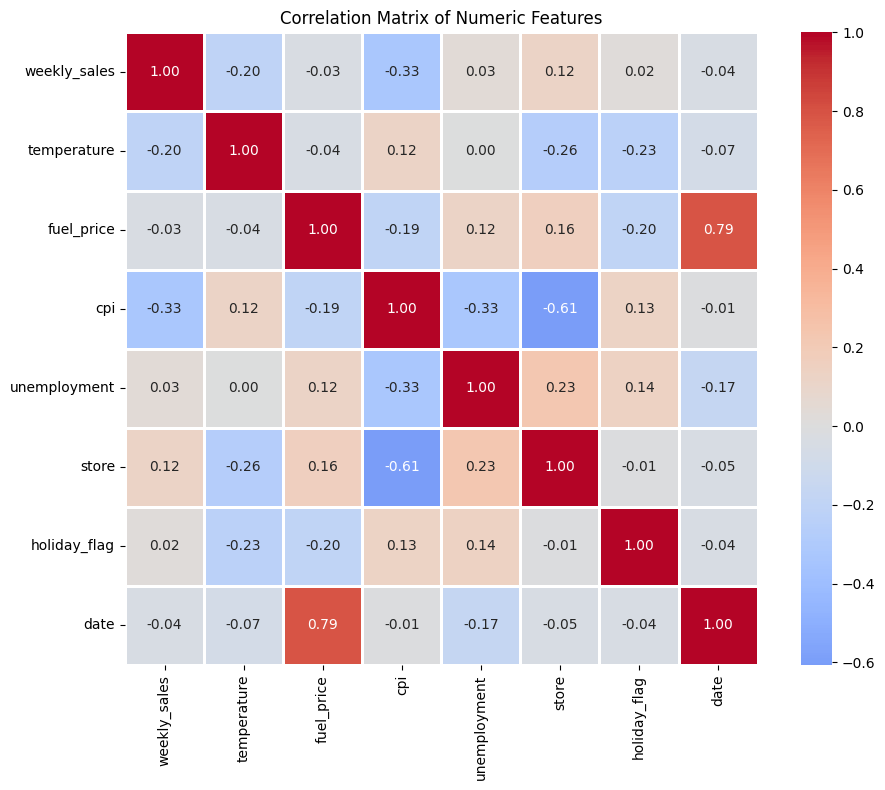

In [22]:
# Plot the correlation matrix as a heatmap
cols = ['weekly_sales', 'temperature', 'fuel_price', 'cpi', 'unemployment', 'store', 'holiday_flag', 'date']

corr_matrix = df[cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f', square=True, linewidths=1)
plt.title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.show()

## Plot pairwise relationshipps between selected features

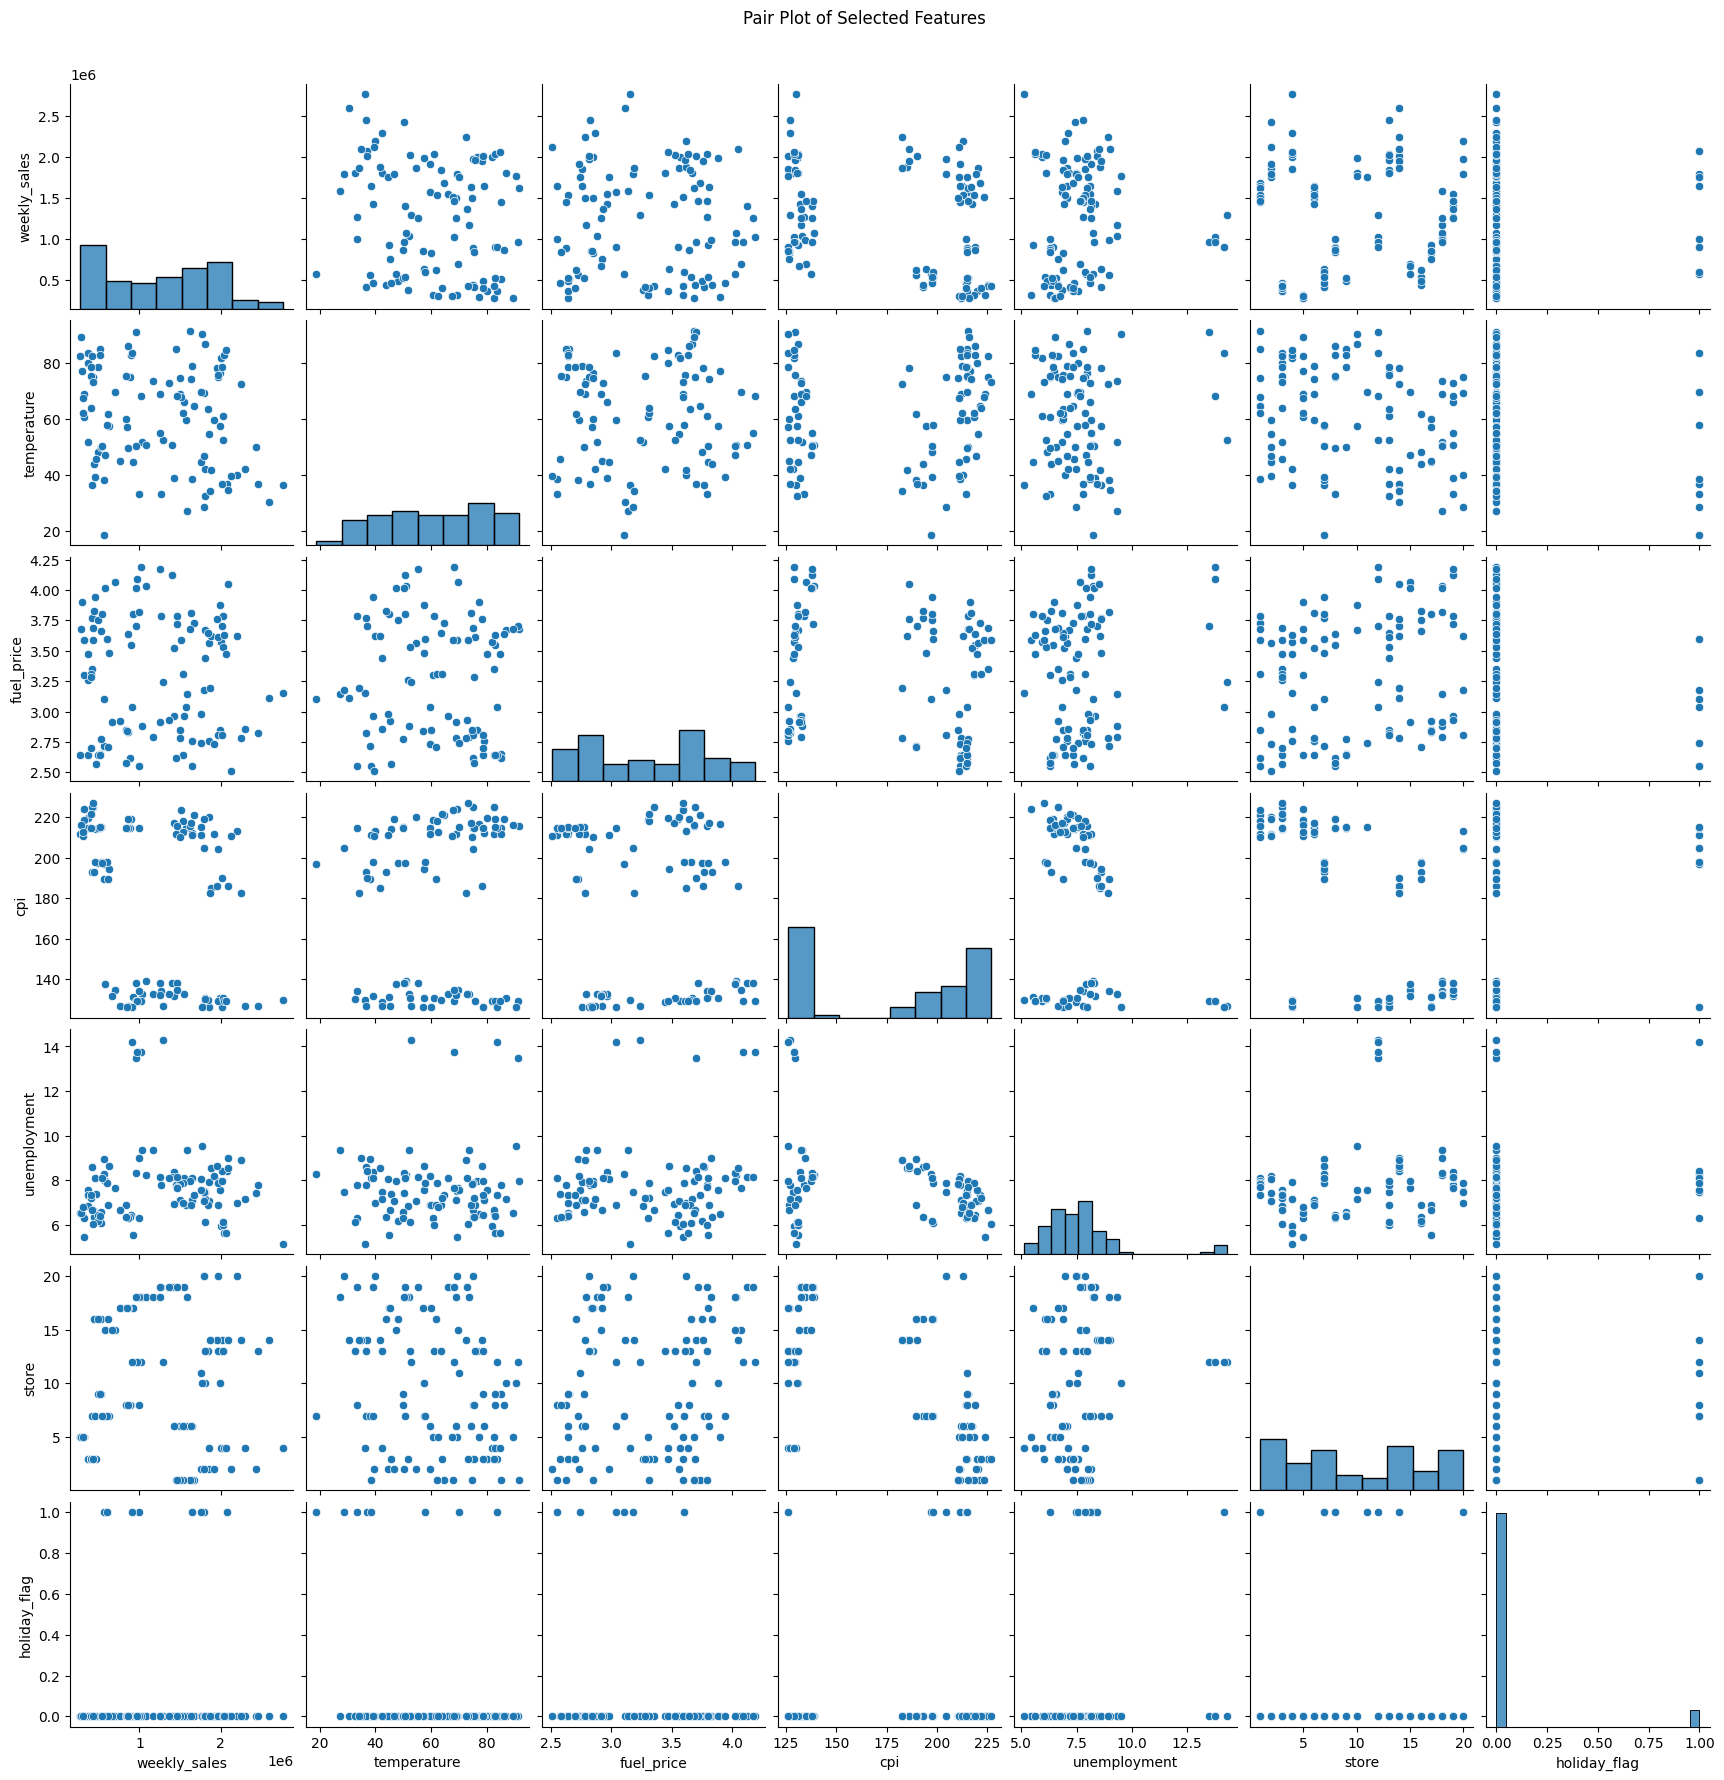

In [23]:

sns.pairplot(df, vars=['weekly_sales', 'temperature', 'fuel_price','cpi', 'unemployment', 'store', 'holiday_flag'])
plt.suptitle('Pair Plot of Selected Features', y=1.02)
plt.show()

In this project, we consider as outliers all the numeric features that don't fall within the range : [Xˉ−3σ,Xˉ+3σ][Xˉ−3σ,Xˉ+3σ]. Five states have a higher rate of unemployment. The 3 sigmas rule indicates statically outlyers on normal distributions. The rule aims errors, abnormal datas. Yet unemployment is a fact in america, not an error. This element should be discussed. I recommend to keep these elements. 

## univariate analysis

target = Weekly_Sales

Dataset de petite taille. Avons-nous suffisamment de données ?

In [24]:
import plotly.io as pio

print(df.value_counts("weekly_sales"))
fig = px.histogram(df["weekly_sales"], 
                   color_discrete_sequence=px.colors.qualitative.Plotly, 
                   title="Distribution de la variable 'weekly_sales'")
fig.show()

weekly_sales
1572117.54    1
1807545.43    1
1644470.66    1
1857533.70    1
695396.19     1
             ..
424513.08     1
2248645.59    1
845252.21     1
856796.10     1
1255087.26    1
Name: count, Length: 118, dtype: int64


La distribution de la variable exploratoire weekly_sales est déséquilibrée, avec une majorité d'achats réalisée en semaine.

Cela peut également poser des problèmes pour l'entraînement d'un modèle de machine learning, car il pourrait être biaisé vers la classe majoritaire.

Il sera important de prendre en compte ce déséquilibre lors du choix des métriques d'évaluation et éventuellement d'utiliser des techniques de rééchantillonnage ou de pondération pour améliorer les performances du modèle sur la classe minoritaire.   

In [25]:
df.value_counts("store")

print(df.value_counts("store"))
fig = px.histogram(df["store"], 
                   title="Distribution de la variable 'store'", 
                   color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

store
3     10
13     9
14     9
1      8
19     8
18     7
7      7
5      7
6      6
4      6
8      6
2      6
17     5
12     5
20     4
16     4
9      4
15     3
10     3
11     1
Name: count, dtype: int64


In [26]:
df_store = df['store'].value_counts().reset_index()
fig = px.pie(df_store.sort_values("store"),
             names = "store", 
             values = "count", 
             title = "Stores proportions", 
             labels={"count": "number"},
            color_discrete_sequence = px.colors.qualitative.Plotly)
fig.show()

Nous observons 20 magasins. Le nombre de relevés varie de 3 à 15 par magasin. Ces enregistrements multiples indiques une variation des variables explicatives date, température, fuel_price, cpi, unemployment.

In [27]:
print(df.loc[df['store'] == 3])


     store       date  weekly_sales  holiday_flag  temperature  fuel_price  \
26       3 2012-01-13     367438.62             0        51.86        3.26   
36       3 2011-09-23     365248.94             0        80.19        3.47   
67       3 2010-02-05     461622.22             0        45.71        2.57   
87       3 2012-05-11     431985.36             0        75.19        3.69   
100      3 2010-06-18     364076.85             0        83.52        2.64   
104      3 2012-06-22     419497.95             0        82.70        3.35   
125      3 2011-11-18     398838.97             0        63.91        3.31   
142      3 2011-10-07     403342.40             0        75.54        3.28   
143      3 2010-06-04     396968.80             0        78.53        2.70   
144      3 2012-10-19     424513.08             0        73.44        3.59   

        cpi  unemployment  year  month  day  weekday  
26      NaN          6.83  2012      1   13        4  
36   219.74          7.57  2011

In [28]:
date_min = min(df['date'])
date_max = max(df['date'])
print(f'date minimum : {date_min} \ndate maximum : {date_max}')


date minimum : 2010-02-05 00:00:00 
date maximum : 2012-10-19 00:00:00


Les relevés correspondent à la période du 5/02/2010 au 19/10/2012.

In [29]:
fig = go.Figure(
    data = go.Histogram(
        x = df['date'], nbinsx = df['date'].nunique()),
    layout = go.Layout(
        title = go.layout.Title(text = "Number of observations per day", x = 0.5),
        xaxis = go.layout.XAxis(title = 'X', rangeslider = go.layout.xaxis.Rangeslider(visible = True))
    )
)

fig.show()

We observe many statements per date.

In [30]:
print(df.loc[df['date'] == '07-01-2011'])

Empty DataFrame
Columns: [store, date, weekly_sales, holiday_flag, temperature, fuel_price, cpi, unemployment, year, month, day, weekday]
Index: []


In [31]:
df_holiday_flag = df["holiday_flag"].map({0.0: "0 (working days)", 1.0: "1 (holidays)"}).value_counts().reset_index() # personalized labels
fig = px.pie(df_holiday_flag,
             names = "holiday_flag", 
             values = "count", 
             title = "Working days vs holidays proportion", 
             labels={"count": "number"})
import plotly.express as px

fig.show()

In [32]:
fig = px.histogram(df["temperature"], title="Distribution de la variable 'Temperature'", color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

Les données sur la température sont abondantes.

In [33]:
fig = px.histogram(df["fuel_price"], title="Distribution de la variable 'Fuel_Price'", color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

In [34]:
fig = px.histogram(df["cpi"], title="Distribution de la variable 'CPI'", color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

In [35]:
fig = px.histogram(df["unemployment"], title="Distribution de la variable 'unemployment'", color_discrete_sequence=px.colors.qualitative.Plotly)
fig.show()

## multivariate analysis

In [36]:
'''sales = df.groupby("store")["weekly_sales"].sum().sort_values(ascending=False).reset_index()
sales["store"] = sales["store"].astype(str)

fig = px.bar(df, x="store", y="weekly_sales", color="store", title="weekly_sales per store", category_orders={"store": sales["store"].tolist()})
fig.update_xaxes(type="category")
fig.show() 
# somme des ventes
# système de couleur par store'''

'sales = df.groupby("store")["weekly_sales"].sum().sort_values(ascending=False).reset_index()\nsales["store"] = sales["store"].astype(str)\n\nfig = px.bar(df, x="store", y="weekly_sales", color="store", title="weekly_sales per store", category_orders={"store": sales["store"].tolist()})\nfig.update_xaxes(type="category")\nfig.show() \n# somme des ventes\n# système de couleur par store'

In [37]:
sales = df.groupby("store")["weekly_sales"].sum().sort_values(ascending=False).reset_index()
statements_nb = df.groupby("store")["weekly_sales"].count()

fig = px.bar(sales, x="store", y="weekly_sales", color="store", title="weekly_sales per store")
fig.update_xaxes(type="category")
fig.show()

In [38]:
statement_nb = df.groupby("store")["weekly_sales"].count()
print(statement_nb)

store
1      8
2      6
3     10
4      6
5      7
6      6
7      7
8      6
9      4
10     3
11     1
12     5
13     9
14     9
15     3
16     4
17     5
18     7
19     8
20     4
Name: weekly_sales, dtype: int64


In [39]:
print(df.loc[df['store'] == 12])

     store       date  weekly_sales  holiday_flag  temperature  fuel_price  \
30      12 2011-05-06    1021154.48             0        68.40        4.19   
62      12 2010-12-17    1295605.35             0        52.77        3.24   
68      12 2011-08-12     955913.68             0        91.04        3.70   
93      12 2011-05-27     964332.51             0          NaN        4.09   
135     12 2010-09-10     903119.03             1        83.63        3.04   

        cpi  unemployment  year  month  day  weekday  
30   129.04         13.74  2011      5    6        4  
62   126.88         14.31  2010     12   17        4  
68   129.20         13.50  2011      8   12        4  
93   129.06         13.74  2011      5   27        4  
135  126.11         14.18  2010      9   10        4  


- top 3 = 14, 13 et 2
- Les ventes n'augmentent pas avec le nombre de relevés : store 3 15 relevés 1/4 des ventes réalisées par le store 14. 
- Le store 12 n'existe pas. Il n'y a que 19 magasins.

Relationship between weekly sales and unemployment

In [40]:
import plotly.express as px
default_stores = [14, 3, 2, 16, 9 ]  # vos 5 stores
fig = px.scatter(df[df['store'].isin(default_stores)], x="unemployment", color="store",
                 title="Weekly_sales vs unemployment : top 2 vs worst 3")
fig.show()

In [41]:
fig = px.scatter(df, x="unemployment", y="weekly_sales", color=df["store"].astype(str),
                 labels={"color": "store"}, title="Weekly_sales vs unemployment")
           
fig.show()

In [42]:
default = [1, 2, 4, 13, 19]  # vos 5 stores

fig = px.scatter(df, x="unemployment", y="weekly_sales",
                 color=df["store"].astype(str),
                 labels={"color": "store"},
                 hover_data={"store": True},
                 title="weekly_sales and unemployment — cliquez sur la légende")

# Cacher tous les stores sauf les 5 par défaut
fig.for_each_trace(lambda t: t.update(visible="legendonly")
                   if t.name not in [str(d) for d in default] else None)
fig.show()

In [43]:
'''import matplotlib.pyplot as plt
d = df.groupby("date").agg({"weekly_sales": "sum", "unemployment": "mean"})
d.plot(subplots=True, figsize=(16, 4))
plt.show()'''

'import matplotlib.pyplot as plt\nd = df.groupby("date").agg({"weekly_sales": "sum", "unemployment": "mean"})\nd.plot(subplots=True, figsize=(16, 4))\nplt.show()'

In [44]:
from plotly.subplots import make_subplots

d = df.groupby("date").agg(unemployment=("unemployment", "mean"),
                           weekly_sales=("weekly_sales", "sum")).reset_index()

fig = make_subplots(rows=2, cols=1, shared_xaxes=True)
fig.add_scatter(x=d["date"], y=d["weekly_sales"], name="weekly_sales", row=1, col=1)
fig.add_scatter(x=d["date"], y=d["unemployment"], name="unemployment", row=2, col=1)
fig.show()





In [45]:
d = df.groupby("store").agg(weekly_sales=("weekly_sales", "sum"),
                            fuel_price=("fuel_price", "mean")).reset_index()
fig = px.scatter_3d(df, x = "store", y = "fuel_price", z = "weekly_sales", color = "weekly_sales", title='Relationship between weekly sales and fuel price')
fig.show()

In [46]:
d = df.groupby("store").agg(weekly_sales=("weekly_sales", "sum"),
                            fuel_price=("fuel_price", "mean")).reset_index()

fig = px.scatter(d, x="store", y="fuel_price", size="weekly_sales", color="weekly_sales", title='Relationship between weekly sales and fuel price')

fig.show()

In [47]:
d = df.groupby("store").agg(weekly_sales=("weekly_sales", "sum"),
                            cpi=("cpi", "mean")).reset_index()

fig = px.scatter(d, x="store", y="cpi", size="weekly_sales", color="weekly_sales", title='Relationship between weekly sales and cpi')

fig.show()

In [48]:
sales = df.groupby("store")["weekly_sales"].sum().sort_values(ascending=False).reset_index()
sales["store"] = sales["store"].astype(int).astype(str)
statements_nb = df.groupby("store")["weekly_sales"].count()

fig = px.bar(sales, x="store", y="weekly_sales", color="store", title="Relationship between weekly sales and stores")
fig.update_xaxes(type="category")
fig.show()

TO DO ajouter la médiane. Colorier seulement les store qui font mieux que la médiane.

Question : évolution du nombre de magasins dans le temps ?

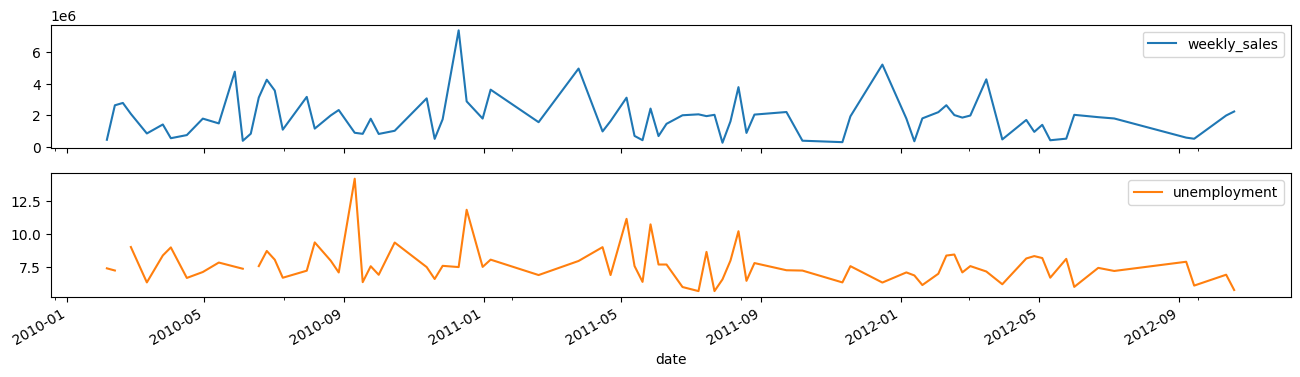

In [49]:
import matplotlib.pyplot as plt
d = df.groupby("date").agg({"weekly_sales": "sum", "unemployment": "mean"})
d.plot(subplots=True, figsize=(16, 4))
plt.show()

In [50]:
df.columns

Index(['store', 'date', 'weekly_sales', 'holiday_flag', 'temperature',
       'fuel_price', 'cpi', 'unemployment', 'year', 'month', 'day', 'weekday'],
      dtype='str')

In [51]:
type(holiday_flag)

pandas.Series

In [52]:
fig = px.scatter(df, x="date", y="weekly_sales", size="weekly_sales",
                 color=df["holiday_flag"].astype(str),
                 color_discrete_map={"0": "blue", "1": "red"},
                 labels={"color": "holiday_flag", "date": "Date",
                         "weekly_sales": "Weekly sales"},
                 title='Relationship between weekly sales and dates, working days vs holidays')

fig.show()